до этого работали ток с координатами кафе но будем теперь работать не только с существующими кафе 

epsg:4326
MultiPolygon    1
Name: count, dtype: int64
(1, 17)


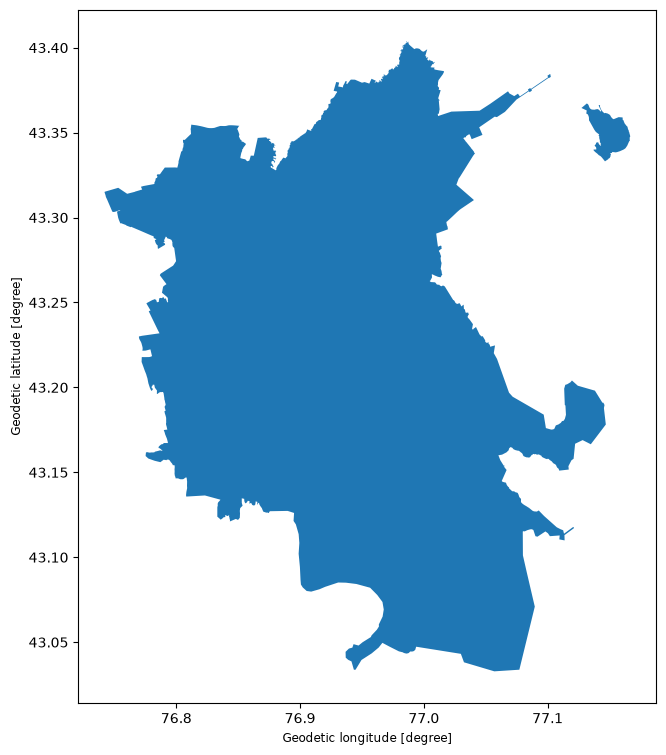

In [ ]:
import osmnx as ox
import geopandas as gpd
import matplotlib.pyplot as plt

place = "Almaty, Kazakhstan"

almaty = ox.geocode_to_gdf(place) # получаем географическую границу из территории

print(almaty.crs) 
print(almaty.geometry.geom_type.value_counts())
print(almaty.shape)

almaty.plot(figsize=(9,9))
plt.show()

#получили географическую карту Алматы чтобы потом исключать ненужные нам регоины, по типу горы и тд
#мы получили территорию в градусах
#территория так же состоит из нескольких полигонов


In [ ]:
# перевод границ в метры

metrics_crs = almaty.estimate_utm_crs()
almaty_m = almaty.to_crs(metrics_crs)

print(almaty_m.crs)

#перевели в метры


EPSG:32643


In [ ]:
minX, minY, maxX, maxY = almaty_m.total_bounds

print(f'minX: {minX}')
print(f'minY: {minY}')
print(f'maxX: {maxX}')
print(f'maxY: {maxY}')

#создаются границы для создания прямоугольника который покрывает наш полигон
#а точнее карту Алмайти
#minX/minY - sleva, maxX/maxY - sprava

minX: 641265.5888651052
minY: 4766397.813012956
maxX: 675610.4805611279
maxY: 4807569.400086247


In [10]:
#np.arange() - создает последовательность чисел с определенным шагом

import numpy as np

x_coords = np.arange(minX, maxX, 500)
y_coords = np.arange(minY, maxY, 500)

In [14]:
from itertools import product

coordinates = list(product(x_coords, y_coords))

#Чтобы получить полноценную сетку, нужно составить все комбинации координат X и Y.

print(len(x_coords))
print(len(y_coords))
print(len(coordinates))

#теперь у нас 5727 потенциальных локаций


69
83
5727


In [ ]:
from shapely.geometry import Point

# point = Point() # создает точки для каждой пары координат в нашем случае для 5727 пар

all_points_for_almaty = []

for i in range(len(coordinates)):
    
    point = Point(coordinates[i])
    all_points_for_almaty.append(point)


for i in range(5):
    print(all_points_for_almaty[i])

#точки созданы

POINT (641265.5888651052 4766397.813012956)
POINT (641265.5888651052 4766897.813012956)
POINT (641265.5888651052 4767397.813012956)
POINT (641265.5888651052 4767897.813012956)
POINT (641265.5888651052 4768397.813012956)


In [17]:
grid = gpd.GeoDataFrame(
    geometry=all_points_for_almaty,
    crs=almaty_m.crs)

print(grid.shape)
print(grid.crs)

(5727, 1)
EPSG:32643


In [35]:
#нужно сделать grid Almighty

city_geometry = almaty_m.geometry.iloc[0]

#происходит векторный цикл который спрашивает ячейка или point внутри алматы или не?
points_inside_city = grid[grid.geometry.within(city_geometry)]

print(len(points_inside_city))


2822


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

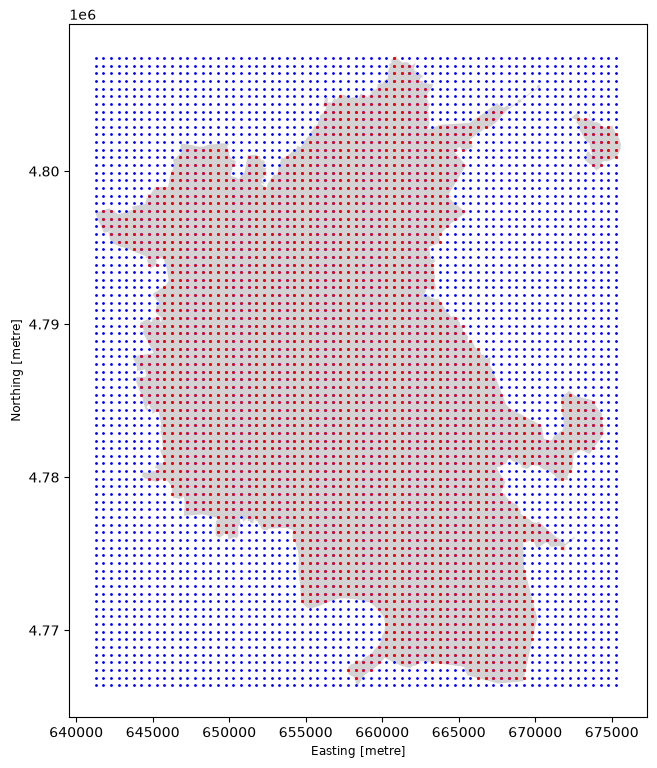

In [45]:
fig, ax = plt.subplots(figsize=(9,9))

almaty_m.plot(ax=ax, color='lightgray', markersize=9) # вся карта алматы

grid.plot(ax=ax, color='blue', markersize=1)

points_inside_city.plot(ax=ax, color='red', markersize=1)